# ToMATo on scikit-learn's cluster comparison datasets

The six datasets of scikit-learn's [clustering comparison](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html),
built and standardized as there, clustered with ToMATo alone (GUDHI, kNN graph, log-DTM density). For each dataset
τ is set to leave the expected number of clusters, and the two neighbor counts are the ones whose clustering best
matches the true labels (ARI).

In [1]:
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gudhi.clustering.tomato import Tomato
from sklearn import datasets
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

## Datasets

In [3]:
# as in scikit-learn's plot_cluster_comparison example
n_samples = 500
seed = 30
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05, random_state=seed)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05, random_state=seed)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=seed)
rng = np.random.RandomState(seed)
no_structure = rng.rand(n_samples, 2), None

random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
aniso = (np.dot(X, transformation), y)
varied = datasets.make_blobs(n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state)

# name: (standardized X, true labels, expected clusters); no_structure is one cluster
DATA = {}
for name, (X, y) in {"noisy_circles": noisy_circles, "noisy_moons": noisy_moons, "varied": varied,
                     "aniso": aniso, "blobs": blobs, "no_structure": no_structure}.items():
    y = np.zeros(len(X), dtype=int) if y is None else y
    DATA[name] = (StandardScaler().fit_transform(X), y, np.unique(y).size)

## Tuning

For each pair of neighbor counts, τ is the midpoint of the prominence interval that leaves the expected number of
clusters (τ = ∞ when the graph's connected components alone make that number). Per dataset the best ARI against
the true labels wins, ties to the widest interval.

In [4]:
K_DENS = (5, 10, 15, 20, 30, 50, 75, 100)     # k_DTM: neighbors in the density estimate, the point included
K_GRAPH = (3, 5, 10, 15, 20, 30)              # k: neighbors in the graph, the point included


def tau_for(model, n):
    """(tau, gap) leaving n clusters: tau midway between the prominence of the last peak kept and of the first
    merged, gap the width of that interval.  inf when the graph's components alone make n clusters; None when
    they make more, or the two prominences tie."""
    dgm = np.asarray(model.diagram_, dtype=float).reshape(-1, 2)
    prom = np.sort(dgm.max(axis=1) - dgm.min(axis=1))[::-1]
    keep = n - len(model.max_weight_per_cc_)   # finite peaks that must survive
    if keep < 0 or keep > prom.size:
        return None
    hi = prom[keep - 1] if keep else np.inf
    lo = prom[keep] if keep < prom.size else 0.0
    if hi <= lo:
        return None
    return (lo + hi) / 2 if keep else np.inf, hi - lo


rows = []
for name, (X, y, n) in DATA.items():
    for kd, kg in itertools.product(K_DENS, K_GRAPH):
        model = Tomato(graph_type="knn", density_type="logDTM", k=kg, k_DTM=kd).fit(X)
        found = tau_for(model, n)
        if found is None:
            continue
        model.merge_threshold_ = found[0]
        if model.n_clusters_ != n:
            raise ValueError(f"{name}, k_dens {kd}, k_graph {kg}: tau {found[0]} left {model.n_clusters_} clusters")
        rows.append({"dataset": name, "expected clusters": n, "k_dens": kd, "k_graph": kg, "tau": found[0],
                     "gap": found[1], "ARI": adjusted_rand_score(y, model.labels_)})
scores = pd.DataFrame(rows)
# per dataset: the best ARI against the true labels, ties to the widest gap
best = (scores.sort_values(["ARI", "gap"], ascending=False, kind="stable")
        .groupby("dataset", sort=False).head(1).set_index("dataset").loc[list(DATA)])
best.round(3)

,expected clusters,k_dens,k_graph,tau,gap,ARI
dataset,,,,,,
noisy_circles,2,5,5,inf,inf,1.000
noisy_moons,2,5,10,inf,inf,1.000
varied,3,5,5,2.372,1.044,0.880
aniso,3,5,10,3.212,2.062,0.982
blobs,3,10,20,1.252,1.744,0.982
no_structure,1,5,5,inf,inf,1.000


## Results

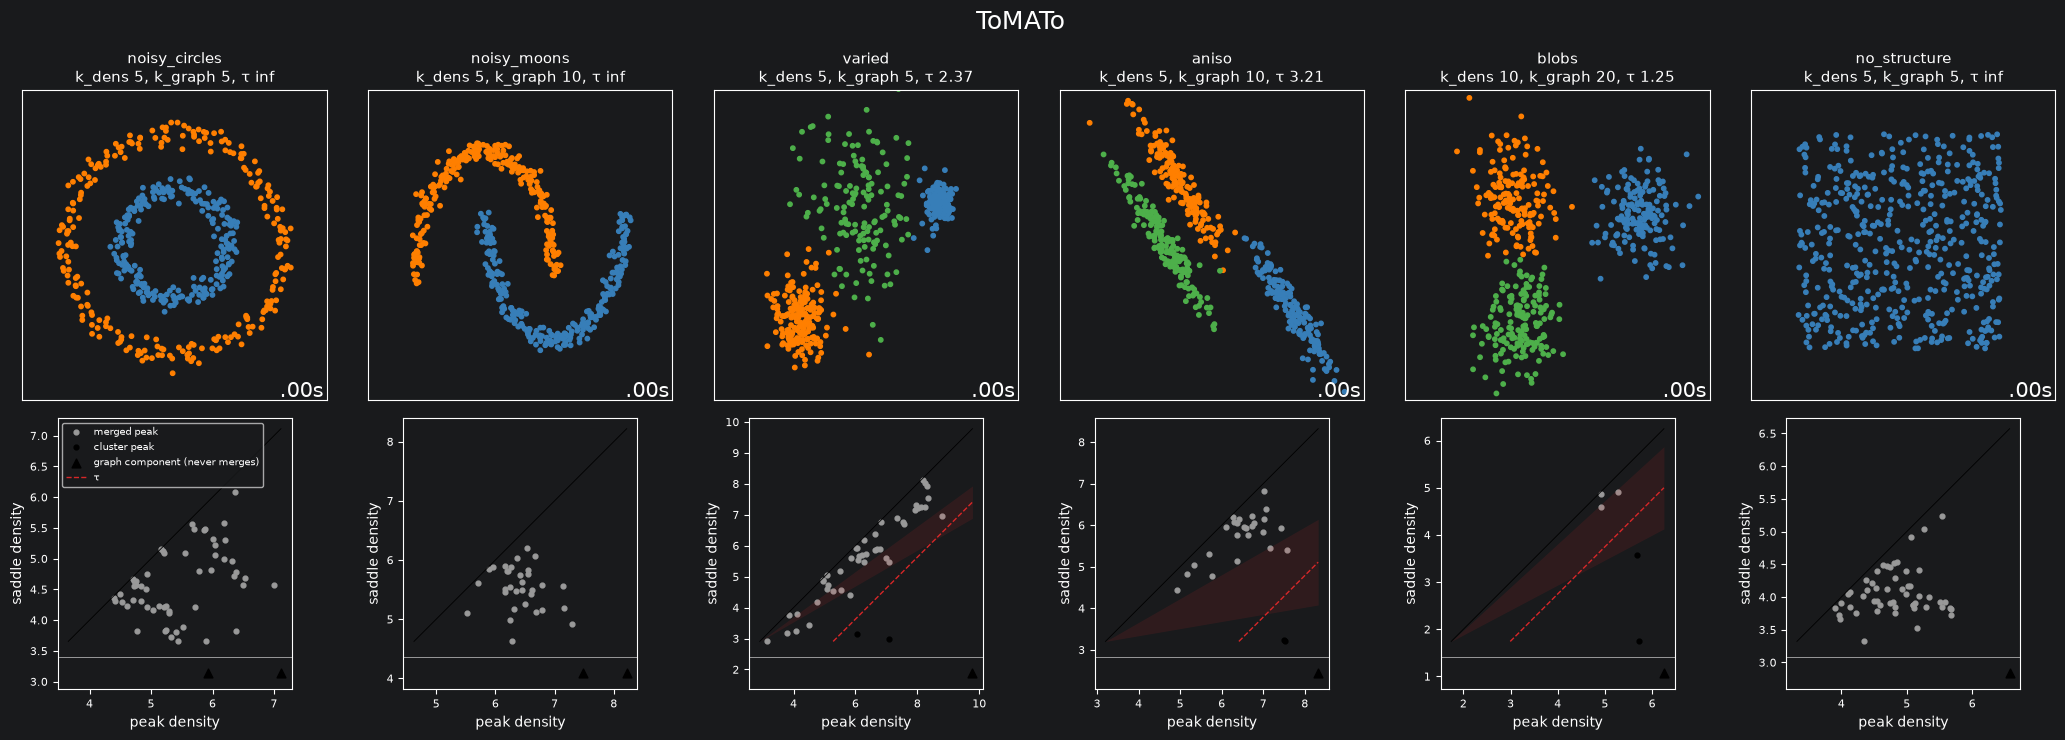

In [6]:
COLORS = np.array(["#377eb8", "#ff7f00", "#4daf4a", "#f781bf", "#a65628", "#984ea3", "#999999", "#e41a1c", "#dede00"])


def diagram_panel(ax, model, tau, gap):
    """Persistence diagram: each density peak at (its density, the saddle density where it merges), and the graph's
    connected components, which never merge, on the strip below.  A peak's prominence is its distance below the
    diagonal; peaks kept are black, merged ones gray, tau is dashed and the band of tau leaving the same clusters
    is shaded."""
    dgm = np.asarray(model.diagram_, dtype=float).reshape(-1, 2)
    birth, death = dgm.max(axis=1), dgm.min(axis=1)
    inf_birth = np.asarray(model.max_weight_per_cc_, dtype=float)
    lo, hi = min(death.min(initial=np.inf), inf_birth.min()), max(birth.max(initial=-np.inf), inf_birth.max())
    pad = 0.05 * (hi - lo)
    y_inf = lo - 3 * pad
    kept = birth - death > tau
    ax.scatter(birth[~kept], death[~kept], s=12, color="0.6", label="merged peak")
    ax.scatter(birth[kept], death[kept], s=12, color="k", label="cluster peak")
    ax.scatter(inf_birth, np.full(inf_birth.size, y_inf), marker="^", s=40, color="k",
               label="graph component (never merges)")
    ax.axhline(y_inf + 1.5 * pad, color="0.8", lw=0.5)
    ax.plot([lo, hi], [lo, hi], color="k", lw=0.6)
    if np.isfinite(tau):
        x = np.array([lo, hi])
        ax.fill_between(x, np.maximum(x - tau - gap / 2, lo), np.maximum(x - tau + gap / 2, lo), color="tab:red",
                        alpha=0.12, lw=0)
        if lo + tau < hi:
            ax.plot([lo + tau, hi], [lo, hi - tau], "--", color="tab:red", lw=1, label="τ")
    ax.set(xlim=(lo - pad, hi + pad), ylim=(y_inf - 1.5 * pad, hi + pad), aspect="equal",
           xlabel="peak density", ylabel="saddle density")
    ax.tick_params(labelsize=8)


fig, axes = plt.subplots(2, len(DATA), figsize=(3.5 * len(DATA), 7.5), gridspec_kw={"height_ratios": [4, 3.5]})
for j, (name, (X, y, n)) in enumerate(DATA.items()):
    ax = axes[0, j]
    p = best.loc[name]
    t0 = time.time()
    model = Tomato(graph_type="knn", density_type="logDTM", k=int(p.k_graph), k_DTM=int(p.k_dens)).fit(X)
    model.merge_threshold_ = p.tau
    t1 = time.time()
    ax.scatter(X[:, 0], X[:, 1], s=10, color=COLORS[model.labels_ % COLORS.size])
    ax.set(xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), xticks=(), yticks=())
    ax.set_title(f"{name}\nk_dens {int(p.k_dens)}, k_graph {int(p.k_graph)}, τ {p.tau:.2f}", size=11)
    ax.text(0.99, 0.01, ("%.2fs" % (t1 - t0)).lstrip("0"), transform=ax.transAxes, size=15,
            horizontalalignment="right")
    diagram_panel(axes[1, j], model, p.tau, p.gap)
# one legend, from the panel showing every kind of mark
axes[1, 0].legend(*max((a.get_legend_handles_labels() for a in axes[1]), key=lambda h: len(h[1])), fontsize=7,
                  loc="upper left")
fig.suptitle("ToMATo", size=18)
fig.tight_layout()
plt.show()